**About:** 3D Cellpose cell segmentation — inference and visualisation

The model predicts two things and neither of them is a cell: an interior
probability, and a *flow field* pointing at each cell's centre. Cells appear
only when the flows are followed — every foreground voxel walks along the field
and voxels arriving at the same attractor are the same cell. That is what lets
two nuclei pressed together come apart, where a threshold on a blob map fuses
them.

Read the panels in this order: the flow field first (is the direction right?),
then the reconstruction (did it split them?), then the metrics.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
cd ../src

/data/kaggle-cell-tracking/src


In [3]:
import glob
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from segmentation.dynamics import follow_flows, masks_from_flows
from segmentation.eval import (
    annotated_frames, evaluate, match_nodes, select_eval_samples,
)
from segmentation.flows import FLOW_SCALE, masks_to_flows
from segmentation.predict import (
    SCALE, gt_nodes, load_frame, load_model, normalize, predict_volume, segment_volume,
)
from utils.plot import scatter_by_depth

### Model

In [50]:
LOG_FOLDER = "../logs/2026-08-31/18/"

In [56]:
glob.glob(LOG_FOLDER + "*.pt")

['../logs/2026-08-31/18/ckpt_10000.pt',
 '../logs/2026-08-31/18/ckpt_12000.pt',
 '../logs/2026-08-31/18/ckpt_02000.pt',
 '../logs/2026-08-31/18/ckpt_08000.pt',
 '../logs/2026-08-31/18/ckpt_13000.pt',
 '../logs/2026-08-31/18/ckpt_14000.pt',
 '../logs/2026-08-31/18/ckpt_06000.pt',
 '../logs/2026-08-31/18/ckpt_07000.pt',
 '../logs/2026-08-31/18/ckpt_05000.pt',
 '../logs/2026-08-31/18/ckpt_01000.pt',
 '../logs/2026-08-31/18/ckpt_11000.pt',
 '../logs/2026-08-31/18/ckpt_04000.pt',
 '../logs/2026-08-31/18/ckpt_final.pt',
 '../logs/2026-08-31/18/ckpt_03000.pt',
 '../logs/2026-08-31/18/ckpt_09000.pt',
 '../logs/2026-08-31/18/ckpt_15000.pt']

In [57]:
model, cfg = load_model(LOG_FOLDER, device="cuda", checkpoint=LOG_FOLDER + "ckpt_02000.pt")

### Data

A real frame, not a synthetic one. The model never saw real imagery in
training, so everything below is out of domain — which is the point of looking
at it.

In [69]:
SAMPLE = "6bba_09961292"
T = annotated_frames(SAMPLE, 1)[0]      # the most densely annotated timepoint
print(f"{SAMPLE}  t={T}")

volume = load_frame(SAMPLE, T)
gt = gt_nodes(SAMPLE, T)
print(f"volume {volume.shape} {volume.dtype}   |   {len(gt)} annotated cells")

6bba_09961292  t=9
volume (64, 256, 256) uint16   |   33 annotated cells


In [70]:
# volumes = glob.glob(str("../input/synthetic/v4/static/*.npz"))
# volume = np.load(volumes[0])["volume"]
# gt = np.load(volumes[0])["centroids"]

### Predict

In [71]:
%%time
centroids, cellprob, flows, instance = segment_volume(
    model, volume, normalization=cfg.get("normalization"),
    device="cuda", return_masks=True,
    cellprob_threshold=0.5, n_iter=200,
)
print(f"- {len(centroids)} cells reconstructed   |   cellprob>0.5 on "
      f"{(cellprob > 0.5).mean():.1%} of voxels")

- 369 cells reconstructed   |   cellprob>0.5 on 6.5% of voxels
CPU times: user 216 ms, sys: 19.8 ms, total: 236 ms
Wall time: 236 ms


#### What the network actually outputs

Left, the image. Middle, the interior probability. Right, the flow field drawn
as colour: the y and x components mapped to hue, so each cell should read as a
small colour wheel with its centre at the middle. A cell whose colours are
smeared into its neighbour is a cell the dynamics will merge.

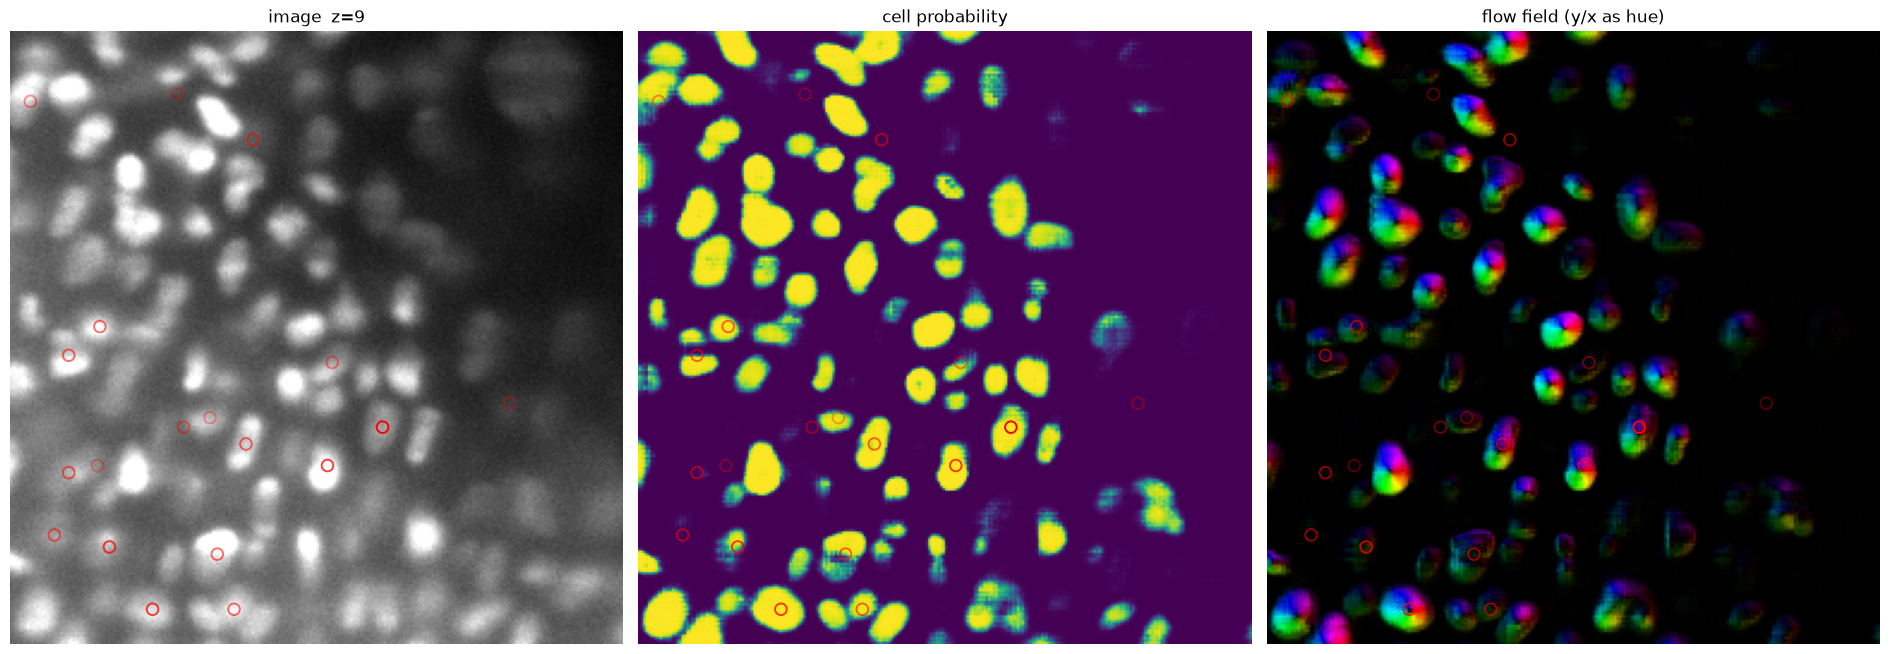

In [72]:
zc = int(np.median(gt[:, 0])) if len(gt) else volume.shape[0] // 2
img_n = normalize(volume, cfg.get("normalization"))

def flow_rgb(f):
    """y/x flow as hue, magnitude as value — the standard optical-flow view."""
    import matplotlib.colors as mcolors
    fy, fx = f[1], f[2]
    ang = (np.arctan2(fy, fx) + np.pi) / (2 * np.pi)
    mag = np.clip(np.sqrt(fy ** 2 + fx ** 2) / FLOW_SCALE, 0, 1)
    hsv = np.stack([ang, np.ones_like(ang), mag], -1)
    return mcolors.hsv_to_rgb(hsv)

fig, axes = plt.subplots(1, 3, figsize=(19, 6.5))
axes[0].imshow(img_n[zc], cmap="gray", vmax=np.percentile(img_n, 99.5))
axes[0].set_title(f"image  z={zc}")
axes[1].imshow(cellprob[zc], cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("cell probability")
axes[2].imshow(flow_rgb(flows[:, zc]))
axes[2].set_title("flow field (y/x as hue)")
for ax in axes:
    scatter_by_depth(ax, gt, zc, "red", tol=5, s=70, linewidths=1.4)
    ax.axis(False)
plt.tight_layout(); plt.show()

#### The reconstruction

Where the trajectories went. Each dot is one foreground voxel at the end of its
walk, coloured by the cell it was assigned to — the tight clumps are the
attractors, and a cell that failed to converge shows up as a smear rather than
a point.

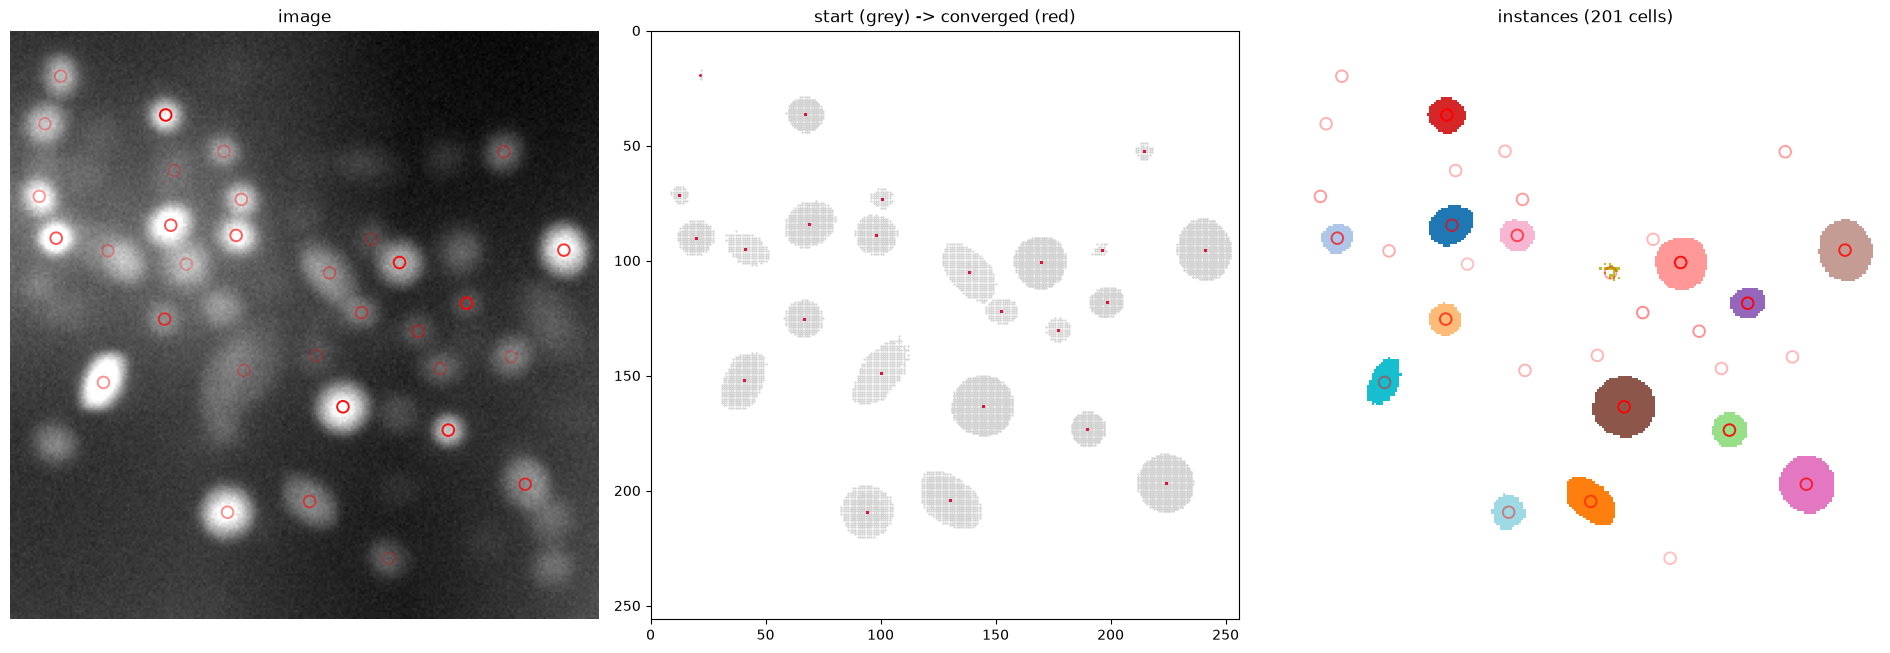

In [66]:
fg = cellprob >= 0.5
start = np.argwhere(fg).astype(np.float32)
final = follow_flows(flows / FLOW_SCALE, start, n_iter=200)

near = np.abs(start[:, 0] - zc) <= 1
fig, axes = plt.subplots(1, 3, figsize=(19, 6.5))
axes[0].imshow(img_n[zc], cmap="gray", vmax=np.percentile(img_n, 99.5))
axes[0].set_title("image")
axes[1].scatter(start[near, 2], start[near, 1], s=0.4, c="lightgrey")
axes[1].scatter(final[near, 2], final[near, 1], s=0.4, c="crimson")
axes[1].set_xlim(0, volume.shape[2])
axes[1].set_ylim(volume.shape[1], 0)
axes[1].set_aspect("equal")
axes[1].set_title("start (grey) -> converged (red)")
lab = np.where(instance[zc] > 0, instance[zc], np.nan)
axes[2].imshow(lab, cmap="tab20", interpolation="nearest")
axes[2].set_title(f"instances ({len(centroids)} cells)")
for ax in (axes[0], axes[2]):
    scatter_by_depth(ax, gt, zc, "red", tol=5, s=70, linewidths=1.4)
    ax.axis(False)
plt.tight_layout()
plt.show()

#### Predicted centres against the annotation

Red circles are annotated cells, cyan crosses are predictions. The annotation
covers ~3% of the cells, so a cyan cross with no red circle is almost always a
real cell nobody labelled — *not* a false positive. Only the red circles
without a cross nearby are misses.

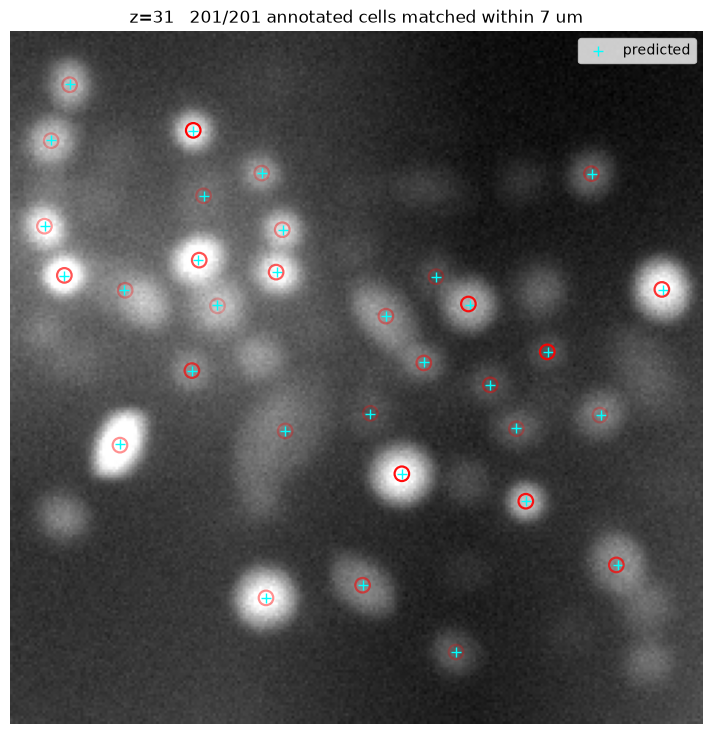

In [67]:
matched = match_nodes(centroids, gt)
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(img_n[zc], cmap="gray", vmax=np.percentile(img_n, 99.5))
near_pred = centroids[np.abs(centroids[:, 0] - zc) <= 5]
ax.scatter(near_pred[:, 2], near_pred[:, 1], marker="+", c="cyan", s=60,
           linewidths=1.0, label="predicted")
scatter_by_depth(ax, gt, zc, "red", tol=5, s=110, linewidths=1.6)
ax.set_title(f"z={zc}   {matched}/{len(gt)} annotated cells matched within 7 um")
ax.legend(loc="upper right"); ax.axis(False)
plt.show()

### Metrics

`node_recall` — the share of annotated cells found, at the 7 um radius.

`adjustment` — the competition's node-count penalty,
`1 - 0.1 * (T_pred - T_true) / T_true`, against the dataset's estimate of the
*true* cell count. Recall alone can be bought by over-predicting; this is what
charges for it. Read the pair.

In [68]:
SAMPLES = select_eval_samples(8)          # 4 stacks per embryo
THRESHOLDS = (0.3, 0.4, 0.5, 0.6, 0.7)
print("samples:", SAMPLES)

# Every threshold shares one forward pass per frame, so the whole sweep costs
# barely more than a single operating point.
summary, per_sample = evaluate(
    model, SAMPLES, max_frames=8, thresholds=THRESHOLDS,
    normalization=cfg.get("normalization"), device="cuda",
)
summary

samples: ['44b6_0113de3b', '44b6_5f15d135', '44b6_abf82518', '44b6_f28707c6', '6bba_05b6850b', '6bba_5a4d9360', '6bba_ae82a791', '6bba_fe670320']
  th 0.30 | recall 0.9626 (463/481) | nodes/frame 246 | adj 0.9545
  th 0.40 | recall 0.9626 (463/481) | nodes/frame 239 | adj 0.9591
  th 0.50 | recall 0.9584 (461/481) | nodes/frame 234 | adj 0.9625
  th 0.60 | recall 0.9584 (461/481) | nodes/frame 228 | adj 0.9665
  th 0.70 | recall 0.9501 (457/481) | nodes/frame 222 | adj 0.9702


,cellprob_threshold,node_recall,adjustment,n_pred_per_frame,n_gt,n_matched,n_samples
0,0.3,0.962578,0.954521,246.312500,481.0,463.0,8.0
1,0.4,0.962578,0.959106,239.484375,481.0,463.0,8.0
2,0.5,0.958420,0.962528,233.875000,481.0,461.0,8.0
3,0.6,0.958420,0.966479,227.890625,481.0,461.0,8.0
4,0.7,0.950104,0.970179,221.828125,481.0,457.0,8.0


#### Threshold sweep

The shape matters more than the best row. Recall that holds while the node
count falls means the flows are right and the probability head is merely
conservative. Recall that collapses as soon as the threshold rises means real
cells are not the model's highest-scoring voxels, and no post-processing
recovers that.

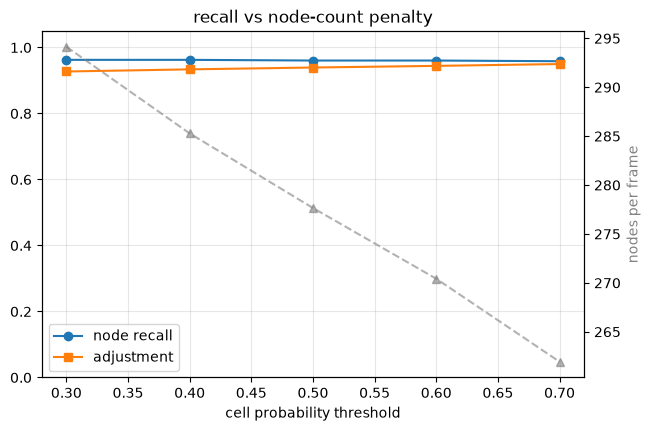

cellprob_threshold,0.3,0.4,0.5,0.6,0.7
sample,,,,,
44b6_0113de3b,1.000000,1.000000,1.000000,1.000000,1.000000
44b6_5f15d135,0.961538,0.961538,0.961538,0.961538,0.923077
44b6_abf82518,1.000000,1.000000,1.000000,1.000000,1.000000
44b6_f28707c6,1.000000,1.000000,1.000000,1.000000,1.000000
6bba_05b6850b,1.000000,1.000000,1.000000,1.000000,1.000000
6bba_5a4d9360,0.818182,0.818182,0.818182,0.818182,0.818182
6bba_ae82a791,1.000000,1.000000,1.000000,1.000000,1.000000
6bba_fe670320,0.990291,0.990291,0.980583,0.980583,0.980583


In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(summary["cellprob_threshold"], summary["node_recall"], "o-", label="node recall")
ax.plot(summary["cellprob_threshold"], summary["adjustment"], "s-", label="adjustment")
ax.set_xlabel("cell probability threshold"); ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3); ax.legend(loc="lower left")
ax.set_title("recall vs node-count penalty")

ax2 = ax.twinx()
ax2.plot(summary["cellprob_threshold"], summary["n_pred_per_frame"], "^--",
         color="grey", alpha=0.6)
ax2.set_ylabel("nodes per frame", color="grey")
plt.show()

# Per stack, so an embryo that behaves differently is visible rather than
# averaged away -- 44b6 runs ~3.4x denser than 6bba.
per_sample.pivot_table(
    index="sample", columns="cellprob_threshold", values="node_recall"
)

### Oracle: the heuristic on ground-truth flows

The control that separates a *model* problem from a *reconstruction* problem.
This feeds the dynamics the exact flows built from a synthetic ground-truth
mask. If this does not recover the cells, no amount of training will help; if
it does, everything missing above is the network's flows, not the heuristic.

In [12]:
d = np.load("../input/synthetic/v3/static/vol_00000.npz")
masks_gt, cen_gt = d["mask"].astype(np.int32), d["centroids"]
cp_gt, fl_gt = masks_to_flows(masks_gt)
_, cen_pred = masks_from_flows(cp_gt, fl_gt * FLOW_SCALE, n_iter=200)

from scipy.spatial import cKDTree
dist, _ = cKDTree(cen_pred * SCALE).query(cen_gt * SCALE, k=1)
print(f"GT {len(cen_gt)} cells -> reconstructed {len(cen_pred)}")
print(f"matched within 7 um: {(dist <= 7).mean():.4f}   "
      f"median error {np.median(dist):.2f} um")

GT 448 cells -> reconstructed 448
matched within 7 um: 1.0000   median error 0.24 um


Done !